<a href="https://colab.research.google.com/github/Rahmatul-Rovi/Capstone-Project-Reports/blob/main/Alzheimers_Disease.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()


In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

rahmatulrovi386_alzheimers_dataset_path = kagglehub.dataset_download('rahmatulrovi386/alzheimers-dataset')

print('Data source import complete.')


In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay)

try:
    from xgboost import XGBClassifier
except ImportError:

    raise

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

os.makedirs("results", exist_ok=True)
print("Setup done.")

Setup done.


In [ ]:
CSV_NAME = "/kaggle/input/datasets/rahmatulrovi386/alzheimers-dataset/alzheimers_prediction_dataset.csv"

if not os.path.exists(CSV_NAME):
    try:
        from google.colab import files
        print("Upload the CSV file")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"{CSV_NAME} Not in the folder. Keep it on the Notebook side.")

df = pd.read_csv(CSV_NAME)
print("Shape:", df.shape)
df.head()

Shape: (74283, 25)


,Country,Age,Gender,Education Level,BMI,Physical Activity Level,Smoking Status,Alcohol Consumption,Diabetes,Hypertension,...,Dietary Habits,Air Pollution Exposure,Employment Status,Marital Status,Genetic Risk Factor (APOE-ε4 allele),Social Engagement Level,Income Level,Stress Levels,Urban vs Rural Living,Alzheimer’s Diagnosis
0,Spain,90,Male,1,33.0,Medium,Never,Occasionally,No,No,...,Healthy,High,Retired,Single,No,Low,Medium,High,Urban,No
1,Argentina,72,Male,7,29.9,Medium,Former,Never,No,No,...,Healthy,Medium,Unemployed,Widowed,No,High,Low,High,Urban,No
2,South Africa,86,Female,19,22.9,High,Current,Occasionally,No,Yes,...,Average,Medium,Employed,Single,No,Low,Medium,High,Rural,No
3,China,53,Male,17,31.2,Low,Never,Regularly,Yes,No,...,Healthy,Medium,Retired,Single,No,High,Medium,Low,Rural,No
4,Sweden,58,Female,3,30.0,High,Former,Never,Yes,No,...,Unhealthy,High,Employed,Married,No,Low,Medium,High,Rural,No


In [ ]:
# Find the Target column
TARGET = [c for c in df.columns if "Diagnosis" in c][0]
print("Target column:", repr(TARGET))

print("\nMissing values :", int(df.isna().sum().sum()))
print("Duplicate rows :", int(df.duplicated().sum()))

print("\nTarget distribution:")
print(df[TARGET].value_counts())
print(df[TARGET].value_counts(normalize=True).round(3))

Target column: 'Alzheimer’s Diagnosis'

Missing values : 0
Duplicate rows : 0

Target distribution:
Alzheimer’s Diagnosis
No     43570
Yes    30713
Name: count, dtype: int64
Alzheimer’s Diagnosis
No     0.587
Yes    0.413
Name: proportion, dtype: float64


In [ ]:
# Column type Changes
y = (df[TARGET] == "Yes").astype(int)          # Yes -> 1, No -> 0
X = df.drop(columns=[TARGET])

numeric_cols     = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(exclude="number").columns.tolist()

print("Numeric columns    :", numeric_cols)
print("Categorical columns:", len(categorical_cols))
print(categorical_cols)

# For Report summary table (Chapter 4.2)
summary = pd.DataFrame({
    "Item": ["Total rows", "Total columns (features)", "Numeric features",
             "Categorical features", "Positive (Yes) rate", "Missing values", "Duplicates"],
    "Value": [len(df), X.shape[1], len(numeric_cols), len(categorical_cols),
              f"{y.mean():.3f}", int(df.isna().sum().sum()), int(df.duplicated().sum())]
})
summary.to_csv("results/dataset_summary.csv", index=False)
summary

Numeric columns    : ['Age', 'Education Level', 'BMI', 'Cognitive Test Score']
Categorical columns: 20
['Country', 'Gender', 'Physical Activity Level', 'Smoking Status', 'Alcohol Consumption', 'Diabetes', 'Hypertension', 'Cholesterol Level', 'Family History of Alzheimer’s', 'Depression Level', 'Sleep Quality', 'Dietary Habits', 'Air Pollution Exposure', 'Employment Status', 'Marital Status', 'Genetic Risk Factor (APOE-ε4 allele)', 'Social Engagement Level', 'Income Level', 'Stress Levels', 'Urban vs Rural Living']


,Item,Value
0,Total rows,74283
1,Total columns (features),24
2,Numeric features,4
3,Categorical features,20
4,Positive (Yes) rate,0.413
5,Missing values,0
6,Duplicates,0


In [ ]:
USE_COUNTRY_AS_FEATURE = False

country = df["Country"].copy()

if not USE_COUNTRY_AS_FEATURE:
    X = X.drop(columns=["Country"])
    categorical_cols = [c for c in categorical_cols if c != "Country"]

print("Final feature count:", X.shape[1])

Final feature count: 23


In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")
print("Positive rate -> train/val/test:",
      round(y_train.mean(),3), round(y_val.mean(),3), round(y_test.mean(),3))

Train: 51998 | Val: 11142 | Test: 11143
Positive rate -> train/val/test: 0.413 0.413 0.413


In [ ]:
# Preprocessing: numeric -> StandardScaler, categorical -> OneHotEncoder
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])

# Just TRAIN fit
preprocessor.fit(X_train)
Xtr = preprocessor.transform(X_train)
Xva = preprocessor.transform(X_val)
Xte = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
print("Features after encoding:", Xtr.shape[1])

Features after encoding: 54


In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                             eval_metric="logloss", random_state=SEED, n_jobs=-1),
    "MLP": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=200,
                         early_stopping=True, random_state=SEED),
}

for name, m in models.items():
    m.fit(Xtr, y_train)
    val_auc = roc_auc_score(y_val, m.predict_proba(Xva)[:, 1])
    print(f"{name:22s} validation AUC = {val_auc:.4f}")

Logistic Regression    validation AUC = 0.7820
XGBoost                validation AUC = 0.7862
MLP                    validation AUC = 0.7834


In [ ]:
rows = []
probs = {}
for name, m in models.items():
    p  = m.predict_proba(Xte)[:, 1]
    yh = (p >= 0.5).astype(int)
    probs[name] = p
    rows.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, yh),
        "Precision": precision_score(y_test, yh),
        "Recall":    recall_score(y_test, yh),
        "F1":        f1_score(y_test, yh),
        "AUC":       roc_auc_score(y_test, p),
    })

results = pd.DataFrame(rows).round(4)
results.to_csv("results/baseline_results.csv", index=False)
results

,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.7108,0.6660,0.6030,0.6329,0.7874
1,XGBoost,0.7205,0.6563,0.6801,0.6679,0.7916
2,MLP,0.7171,0.6541,0.6703,0.6621,0.7907


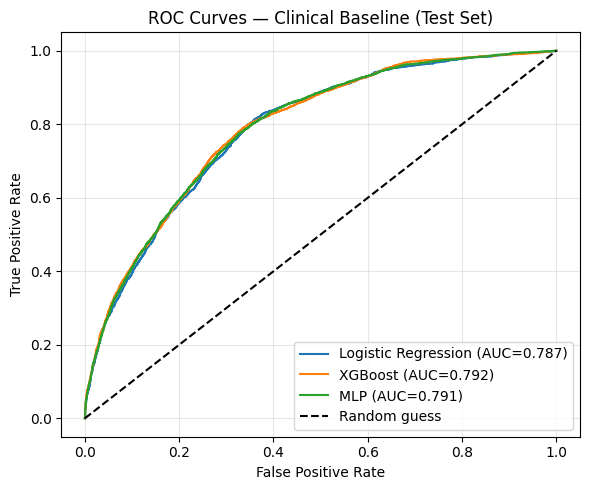

In [ ]:
# ROC curves
plt.figure(figsize=(6, 5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Clinical Baseline (Test Set)")
plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/roc_curves.png", dpi=200)
plt.show()

Best model: XGBoost


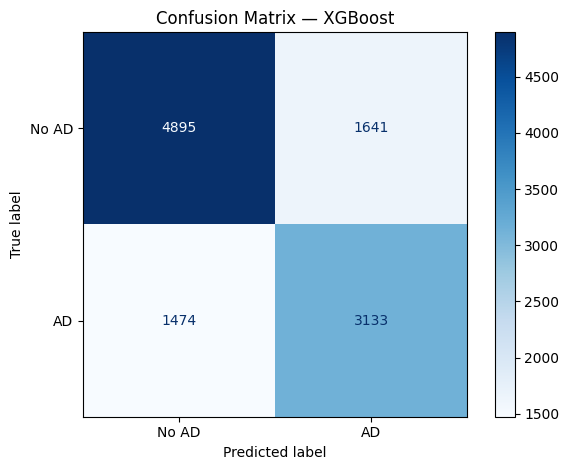

[[4895 1641]
 [1474 3133]]


In [ ]:
# Confusion matrix — for the best model (with the AUC value)
best_name = results.sort_values("AUC", ascending=False).iloc[0]["Model"]
print("Best model:", best_name)

yh_best = (probs[best_name] >= 0.5).astype(int)
cm = confusion_matrix(y_test, yh_best)
ConfusionMatrixDisplay(cm, display_labels=["No AD", "AD"]).plot(cmap="Blues")
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=200)
plt.show()
print(cm)

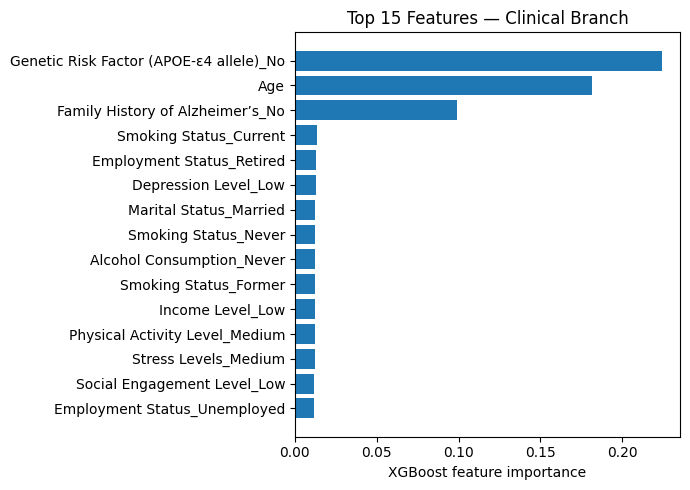

cat__Genetic Risk Factor (APOE-ε4 allele)_No    0.2241
num__Age                                        0.1813
cat__Family History of Alzheimer’s_No           0.0989
cat__Smoking Status_Current                     0.0136
cat__Employment Status_Retired                  0.0131
cat__Depression Level_Low                       0.0127
cat__Marital Status_Married                     0.0126
cat__Smoking Status_Never                       0.0125
cat__Alcohol Consumption_Never                  0.0125
cat__Smoking Status_Former                      0.0124
dtype: float32

In [ ]:
xgb = models["XGBoost"]
imp = pd.Series(xgb.feature_importances_, index=feature_names).sort_values(ascending=False)
top = imp.head(15)[::-1]

plt.figure(figsize=(7, 5))
plt.barh([n.split("__")[-1] for n in top.index], top.values)
plt.xlabel("XGBoost feature importance")
plt.title("Top 15 Features — Clinical Branch")
plt.tight_layout()
plt.savefig("results/feature_importance.png", dpi=200)
plt.show()
imp.head(10).round(4)

In [ ]:
client_df = pd.DataFrame({"Country": country, "AD": y})
clients = (client_df.groupby("Country")["AD"]
           .agg(Samples="size", Positive_Rate="mean")
           .round(3).sort_values("Samples"))
clients.to_csv("results/client_table.csv")

print("Number of clients:", len(clients))
print("Sample size range  :", clients.Samples.min(), "-", clients.Samples.max())
print("Positive-rate range:", clients.Positive_Rate.min(), "-", clients.Positive_Rate.max())
clients

Number of clients: 20
Sample size range  : 3592 - 3839
Positive-rate range: 0.339 - 0.504


,Samples,Positive_Rate
Country,,
China,3592,0.386
Mexico,3598,0.485
USA,3616,0.389
UK,3651,0.404
Saudi Arabia,3662,0.414
Sweden,3689,0.342
Spain,3698,0.400
Norway,3706,0.350
France,3710,0.401
